# Chapter 2 Building Classic Agent Paradigms

- ReAct (Reasoning and Acting): A paradigm that tightly combines "thinking" and "acting," allowing agents to think while doing and dynamically adjust
- Plan-and-solve:A "think before you act" paradigm where agents first generate a complete action plan and then strictly execute it
- Reflection: A paradigm that endows agents with "reflection" capabilities, optimizing results through self-criticism and correction

## 1. Environment Preparation and Basic Tool Definition

We need to set up the development environment and define some basic components. In most cases, Open ai API is more common than the other ones. However, in this guide, We will use some free APIS.

However, you should learn the basic requests way for openAI API

Install dependencies:

In [ ]:
# pip install openai python-dotenv

### 1.1 Configuring API Keys
To make our code more universal, we uniformly configure model service-related information in EV variables
- In your project root directory, create a file named .env
- In this file, add the following content. You can point it to OpenAI's official service or any local/third-party service compatible with the OpenAI interface according to your needs.


In [ ]:
# .env file
LLM_API_KEY="YOUR-API-KEY"
LLM_MODEL_ID="YOUR-MODEL"
LLM_BASE_URL="YOUR-URL"

### 1.2 Encapsulating Basic LLM Call Functions

In order to make the structure of the code more clear, we define a specific LLM client, encapusulating the service and interactions.

In [1]:
import os
from openai import OpenAI
from dotenv import load_dotenv
from typing import List, Dict

# Load environment variables from .env file
load_dotenv()

class HelloAgentsLLM:
    """
    A customized LLM client for the book "Hello Agents".
    It is used to call any service compatible with the OpenAI interface
    and uses streaming responses by default.
    """
    def __init__(self, model: str = None, apiKey: str = None, baseUrl: str = None, timeout: int = None):
        """
        Initialize the client. Prioritize passed parameters; if not provided, load from environment variables.
        """
        self.model = model or os.getenv("LLM_MODEL_ID")
        apiKey = apiKey or os.getenv("LLM_API_KEY")
        baseUrl = baseUrl or os.getenv("LLM_BASE_URL")
        timeout = timeout or int(os.getenv("LLM_TIMEOUT", 60))

        if not all([self.model, apiKey, baseUrl]):
            raise ValueError("Model ID, API key, and service address must be provided or defined in the .env file.")

        self.client = OpenAI(api_key=apiKey, base_url=baseUrl, timeout=timeout)

    def think(self, messages: List[Dict[str, str]], temperature: float = 0) -> str:
        """
        Call the large language model to think and return its response.
        """
        print(f"Calling {self.model} model...")
        try:
            response = self.client.chat.completions.create(
                model=self.model,
                messages=messages,
                temperature=temperature,
                stream=True,
                extra_body={"thinking": {"type": "disabled"}},  # DeepSeek: turn off thinking mode
            )

            # Handle streaming response
            print("Large language model response successful:")
            collected_content = []
            for chunk in response:
                if not chunk.choices:
                    continue
                content = chunk.choices[0].delta.content or ""
                print(content, end="", flush=True)
                collected_content.append(content)
            print()  # Newline after streaming output ends
            return "".join(collected_content)

        except Exception as e:
            print(f"Error occurred when calling LLM API: {e}")
            return None

## 2.ReAct

### 2.1 ReAct Workflow

- pure thinking: COT, chain-of-thought. Guiding models to perfrom complex logical reasoning but cannot interact with the external world
- pure action: models directly output actions to execute but lack planning and error correction

ReAct paradigm uses a prompt engineering to guide the model so that each step of its output follows a fixed trajectory:

- Thought: The agent's mind to analyze the current situation, decomposes tasks, formulate next plan, or refleccts on the results of the previous step
- Action: The specific action that agent decides to take
- Observation: The result returned from the external tool after execuiting the Action  

**Reasoning makes actions more purposeful, while actions provide factural basis for reasoning**

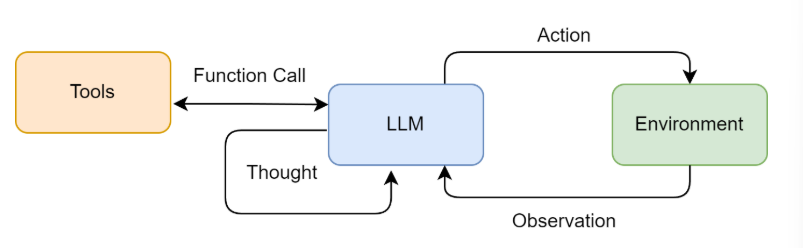

**The suitable scenarios**
- Tasks requiring external knowledge: querying real-time informtion searching for knowledge in professional domains
- Tasks requiring precise calculations:Delegating mathematical problems to calculator tools to avoid errors
- Tasks requiring API interaction: operating databases, calling a service's API to complete functions


### 2.2 Tool and implementation

LLM can be viewed as a brain of an agent, then **tools** are the body parts of the agent. To enable the ReAct paradigm to solve the problem.

Let's say the last example of exchanging rate in chapter 1

### 2.2.1 Implementing the core logic of the tool

A well-defined tool should have three core elements:
- Name: A clear, unique identifier for the agent to call in Action
- Description：A short description of the function of the tool. This is the key part since LLM will judge the time when it would use the tool
- Logic：The true function to finish the task

Here is a exchange-rate tool:

In [2]:
import re
import requests

def get_exchange_rate(query: str) -> str:
    """
    A practical exchange-rate tool based on ExchangeRate-API's open access endpoint.
    It parses the query, fetches the latest rates, and returns only the rate the agent needs.
    """
    print(f"Executing [ExchangeRate-API] lookup: {query}")

    # 1. Parse the query: "<amount> <FROM> to <TO>", the amount is optional
    match = re.match(r"^\s*(\d+(?:\.\d+)?)?\s*([A-Za-z]{3})\s+to\s+([A-Za-z]{3})\s*$",
                     query, re.IGNORECASE)
    if not match:
        return ("Error: Invalid input. Use the format '<amount> <FROM> to <TO>' "
                "with 3-letter currency codes, e.g. '200 USD to EUR'.")
    amount_str = match.group(1)
    base, quote = match.group(2).upper(), match.group(3).upper()

    try:
        # 2. Call the API; the base currency is part of the URL
        response = requests.get(f"https://open.er-api.com/v6/latest/{base}", timeout=15)
        results = response.json()

        # 3. Intelligent parsing: check the status first, then pick out only the rate we need
        if results.get("result") != "success":
            if results.get("error-type") == "unsupported-code":
                return f"Error: Unsupported currency code '{base}'."
            return f"Error: Exchange-rate service returned '{results.get('error-type')}'."

        rate = results["rates"].get(quote)
        if rate is None:
            return f"Error: Unsupported currency code '{quote}'."

        updated = results["time_last_update_utc"]
        source = "Rates By Exchange Rate API (https://www.exchangerate-api.com)"
        if amount_str is None:
            return f"1 {base} = {rate} {quote}. Updated: {updated}. Source: {source}"

        converted = round(float(amount_str) * rate, 2)
        return (f"{amount_str} {base} ≈ {converted} {quote} (rate: 1 {base} = {rate} {quote}). "
                f"Updated: {updated}. Source: {source}. Estimate only; excludes exchange fees.")

    except Exception as e:
        return f"Error occurred during exchange-rate lookup: {e}"

This function has three steps:
- Analyzing the inputs: THe format of the Action is ToolName[tool_input]. However, the tool could just receive a string. So, we use the split function to separte "200 USD to EUR" to amount, base and target.
- Request API
- Analyzing the results: API will return 160 kinds of exchange rates based on base currency in one search. But the agent only needs one. So, this function will check whether the requests is successful, and then only return the exchange rate of target currency, calculate the amount and return the updating time and source in a sentance.


### 2.2.2 Building a General Tool Executor

When agents need different tools, we should construct a "manager" to register and select the appropriate tool for the task. So, we create a class called "ToolExecutor"

In [3]:
from typing import Dict, Any

class ToolExecutor:
    """
    A tool executor responsible for managing and executing tools.
    """
    def __init__(self):
        self.tools: Dict[str, Dict[str, Any]] = {}

    def registerTool(self, name: str, description: str, func: callable):
        """
        Register a new tool in the toolbox.
        """
        if name in self.tools:
            print(f"Warning: Tool '{name}' already exists and will be overwritten.")
        self.tools[name] = {"description": description, "func": func}
        print(f"Tool '{name}' registered.")

    def getTool(self, name: str) -> callable:
        """
        Get a tool's execution function by name.
        """
        return self.tools.get(name, {}).get("func")

    def getAvailableTools(self) -> str:
        """
        Get a formatted description string of all available tools.
        """
        return "\n".join([
            f"- {name}: {info['description']}"
            for name, info in self.tools.items()
        ])

### 2.2.3 Testing
Then, we put the exchange reate tool into the ToolExecutor to simulate, test whether the whole process can work correctly.

In [4]:
# 1. Initialize tool executor
toolExecutor = ToolExecutor()

# 2. Register our exchange-rate tool
exchange_description = (
    "Look up the latest exchange rate between two currencies and convert an amount. "
    "Use this tool whenever the user asks about exchange rates or converting money; "
    "never guess a rate yourself. Input format: '<amount> <FROM> to <TO>' with "
    "3-letter currency codes, e.g. '200 USD to EUR'. Omit the amount to get only "
    "the rate, e.g. 'USD to JPY'."
)
toolExecutor.registerTool("ExchangeRate", exchange_description, get_exchange_rate)

# 3. Print available tools
print("\n--- Available Tools ---")
print(toolExecutor.getAvailableTools())

# 4. Simulate the agent's Action: ExchangeRate[200 USD to EUR]
print("\n--- Execute Action: ExchangeRate['200 USD to EUR'] ---")
tool_name = "ExchangeRate"
tool_input = "200 USD to EUR"

tool_function = toolExecutor.getTool(tool_name)
if tool_function:
    observation = tool_function(tool_input)
    print("--- Observation ---")
    print(observation)
else:
    print(f"Error: Tool named '{tool_name}' not found.")

Tool 'ExchangeRate' registered.

--- Available Tools ---
- ExchangeRate: Look up the latest exchange rate between two currencies and convert an amount. Use this tool whenever the user asks about exchange rates or converting money; never guess a rate yourself. Input format: '<amount> <FROM> to <TO>' with 3-letter currency codes, e.g. '200 USD to EUR'. Omit the amount to get only the rate, e.g. 'USD to JPY'.

--- Execute Action: ExchangeRate['200 USD to EUR'] ---
Executing [ExchangeRate-API] lookup: 200 USD to EUR
--- Observation ---
200 USD ≈ 179.49 EUR (rate: 1 USD = 0.897453 EUR). Updated: Wed, 28 Oct 2026 00:02:31 +0000. Source: Rates By Exchange Rate API (https://www.exchangerate-api.com). Estimate only; excludes exchange fees.


## 2.3 Coidng implementation of ReAct Agnet

Now, let's combine the single tools: LLM cilent, tool executor to build a complete ReAct agent. We will encapsulate its core logic through a ReActAgent class.

### 2.3.1 System prompt

We need design a template that will dynmaically insert available tools, user questions and the interaction history of intermediate steps.

In [5]:
# ReAct Prompt Template
REACT_PROMPT_TEMPLATE = """
Please note that you are an intelligent assistant capable of calling external tools.

Available tools are as follows:
{tools}

Please respond strictly in the following format:

Thought: Your thinking process, used to analyze problems, decompose tasks, and plan the next action.
Action: The action you decide to take, must be in one of the following formats:
- `{{tool_name}}[{{tool_input}}]`: Call an available tool.
- `Finish[final answer]`: When you believe you have obtained the final answer.
- When you have collected enough information to answer the user's final question, you must use `Finish[final answer]` after the Action: field to output the final answer.

Now, please start solving the following problem:
Question: {question}
History: {history}
"""

This templete define the standard interaction between agent and LLM
- The rule: You are an intelligent assistant capable of calling external tools
- Tools: let LLM know its bodies ({tools})
- The format: Enforcing llm outputs structured content, we can precisely parse its intent through code (Thought/Action)
- Daynamic context: Injects the user's original question and continuously accumulated interaction history, allowing the LLM to make decisions based on context.({question}/{history})

### 2.3.2 The core loop

Formats prompt -> call LLM -> executes action -> integrates results

In [6]:
class ReActAgent:
    def __init__(self, llm_client: HelloAgentsLLM, tool_executor: ToolExecutor, max_steps: int = 5):
        self.llm_client = llm_client
        self.tool_executor = tool_executor
        self.max_steps = max_steps
        self.history = []

    def run(self, question: str):
        """
        Run the ReAct agent to answer a question.
        """
        self.history = []  # Reset history for each run
        current_step = 0

        while current_step < self.max_steps:
            current_step += 1
            print(f"--- Step {current_step} ---")

            # (1) Format prompt
            tools_desc = self.tool_executor.getAvailableTools()
            history_str = "\n".join(self.history)
            prompt = REACT_PROMPT_TEMPLATE.format(
                tools=tools_desc,
                question=question,
                history=history_str
            )

            # (2) Call LLM to think
            messages = [{"role": "user", "content": prompt}]
            response_text = self.llm_client.think(messages=messages)

            if not response_text:
                print("Error: LLM failed to return a valid response.")
                break

            # (3) Parse LLM output
            thought, action = self._parse_output(response_text)

            if thought:
                print(f"Thought: {thought}")

            if not action:
                print("Warning: Failed to parse valid Action, process terminated.")
                break

            # (4) Execute Action
            if action.startswith("Finish"):
                # If it's a Finish instruction, extract the final answer and end
                final_answer = re.match(r"Finish\[(.*)\]", action).group(1)
                print(f"Final Answer: {final_answer}")
                return final_answer

            tool_name, tool_input = self._parse_action(action)
            if not tool_name or not tool_input:
                # Handle invalid Action format: tell the model what went wrong
                self.history.append(f"Action: {action}")
                self.history.append("Observation: Error: Invalid Action format. "
                                    "Use tool_name[tool_input] or Finish[final answer].")
                continue

            print(f"Action: {tool_name}[{tool_input}]")

            tool_function = self.tool_executor.getTool(tool_name)
            if not tool_function:
                observation = f"Error: Tool named '{tool_name}' not found."
            else:
                observation = tool_function(tool_input)  # Call real tool

            # (5) Integrate observation results
            print(f"Observation: {observation}")

            # Add this round's Action and Observation to history
            self.history.append(f"Action: {action}")
            self.history.append(f"Observation: {observation}")

        # Loop ends
        print("Maximum steps reached, process terminated.")
        return None

    def _parse_output(self, text: str):
        """Parse LLM output to extract Thought and Action."""
        # Thought: match until Action: or end of text
        thought_match = re.search(r"Thought:\s*(.*?)(?=\nAction:|$)", text, re.DOTALL)
        # Action: match until end of text
        action_match = re.search(r"Action:\s*(.*?)$", text, re.DOTALL)
        thought = thought_match.group(1).strip() if thought_match else None
        action = action_match.group(1).strip() if action_match else None
        return thought, action

    def _parse_action(self, action_text: str):
        """Parse Action string to extract tool name and input."""
        match = re.match(r"(\w+)\[(.*)\]", action_text, re.DOTALL)
        if match:
            return match.group(1), match.group(2)
        return None, None

### 2.3.3 Output Parser Implementation

LLM returns plain text, and we need to precisely extract Thought and Action from it. This is accomplished thtough several auxiliary parsing functions, which typically use regular expressions.

- _parse_output: Separain the answer from LLM into thought and Action
- _parse_action: Separating the Action

### 2.3.4 Tool invocation and exeution

This code is the execution center of Action. It checks whether it's a Finish instruction; if,so the process ends. Otherwise, it obtains the correspoinding tool function through tool_executor and executes it to get the observation.

### 2.3.5 The integration of the observed results

Appending the results of Action and observation after tool execution back to the history, providing new context for the next loop

The whole loop:

In [7]:
llm_client = HelloAgentsLLM()
agent = ReActAgent(llm_client=llm_client, tool_executor=toolExecutor)
agent.run("I have 200 USD. About how many euros is that? Also, how much is 10000 JPY in CNY?")

--- Step 1 ---
Calling deepseek-v4-pro model...
Large language model response successful:
Thought: The user asks two currency conversion questions: 200 USD to EUR, and 10000 JPY to CNY. I need to use the ExchangeRate tool for both, since I must not guess rates. I'll start with the first conversion.Action: ExchangeRate[200 USD to EUR]
Thought: The user asks two currency conversion questions: 200 USD to EUR, and 10000 JPY to CNY. I need to use the ExchangeRate tool for both, since I must not guess rates. I'll start with the first conversion.Action: ExchangeRate[200 USD to EUR]
Action: ExchangeRate[200 USD to EUR]
Executing [ExchangeRate-API] lookup: 200 USD to EUR
Observation: 200 USD ≈ 179.49 EUR (rate: 1 USD = 0.897453 EUR). Updated: Wed, 28 Oct 2026 00:02:31 +0000. Source: Rates By Exchange Rate API (https://www.exchangerate-api.com). Estimate only; excludes exchange fees.
--- Step 2 ---
Calling deepseek-v4-pro model...
Large language model response successful:
Thought: The user asks 

'200 USD is about 179.49 EUR. 10000 JPY is about 423.07 CNY.'

From the outputs, we can find two questions: The model draw the Thought and Actin in the same row; when the model invocate the tools, it wrote the Finish at first.


In [13]:
# ReAct Prompt Template (with rules that keep the model to one step per reply)
REACT_PROMPT_TEMPLATE = """
Please note that you are an intelligent assistant capable of calling external tools.

Available tools are as follows:
{tools}

Please respond strictly in the following format:

Thought: Your thinking process, used to analyze problems, decompose tasks, and plan the next action.
Action: The action you decide to take, must be in one of the following formats:
- `{{tool_name}}[{{tool_input}}]`: Call an available tool.
- `Finish[final answer]`: When you believe you have obtained the final answer.
- When you have collected enough information to answer the user's final question, you must use `Finish[final answer]` after the Action: field to output the final answer.

Rules:
- Each response must contain exactly one Thought and one Action. Stop right after the Action and wait for the Observation.
- Never write an Observation yourself. It will be provided after the tool runs.
- Never put Finish in the same response as a tool call. Use Finish only after you have seen every Observation you need.

Now, please start solving the following problem:
Question: {question}
History: {history}
"""

To bear the error of the format bias

In [14]:
class ReActAgent:
    def __init__(self, llm_client: HelloAgentsLLM, tool_executor: ToolExecutor, max_steps: int = 5):
        self.llm_client = llm_client
        self.tool_executor = tool_executor
        self.max_steps = max_steps
        self.history = []

    def run(self, question: str):
        """
        Run the ReAct agent to answer a question.
        """
        self.history = []  # Reset history for each run
        current_step = 0

        while current_step < self.max_steps:
            current_step += 1
            print(f"--- Step {current_step} ---")

            # (1) Format prompt
            tools_desc = self.tool_executor.getAvailableTools()
            history_str = "\n".join(self.history)
            prompt = REACT_PROMPT_TEMPLATE.format(
                tools=tools_desc,
                question=question,
                history=history_str
            )

            # (2) Call LLM to think
            messages = [{"role": "user", "content": prompt}]
            response_text = self.llm_client.think(messages=messages)

            if not response_text:
                print("Error: LLM failed to return a valid response.")
                break

            # (3) Parse LLM output
            thought, action = self._parse_output(response_text)

            if thought:
                print(f"Thought: {thought}")

            if not action:
                print("Warning: Failed to parse valid Action, process terminated.")
                break

            # (4) Execute Action
            if action.startswith("Finish"):
                # re.DOTALL lets the final answer span several lines
                finish_match = re.match(r"Finish\[(.*)\]", action, re.DOTALL)
                if finish_match:
                    final_answer = finish_match.group(1).strip()
                    print(f"Final Answer: {final_answer}")
                    return final_answer
                # Finish without brackets: tell the model instead of crashing
                self.history.append(f"Action: {action}")
                self.history.append("Observation: Error: Invalid Finish format. Use Finish[final answer].")
                continue

            tool_name, tool_input = self._parse_action(action)
            if not tool_name or not tool_input:
                # Handle invalid Action format: tell the model what went wrong
                self.history.append(f"Action: {action}")
                self.history.append("Observation: Error: Invalid Action format. "
                                    "Use tool_name[tool_input] or Finish[final answer].")
                continue

            print(f"Action: {tool_name}[{tool_input}]")

            tool_function = self.tool_executor.getTool(tool_name)
            if not tool_function:
                observation = f"Error: Tool named '{tool_name}' not found."
            else:
                observation = tool_function(tool_input)  # Call real tool

            # (5) Integrate observation results
            print(f"Observation: {observation}")

            # Add this round's Action and Observation to history
            self.history.append(f"Action: {action}")
            self.history.append(f"Observation: {observation}")

        # Loop ends
        print("Maximum steps reached, process terminated.")
        return None

    def _parse_output(self, text: str):
        """Parse LLM output to extract Thought and Action."""
        # Remove markdown bold, so **Thought**: and **Action**: still match
        text = text.replace("**", "")
        # Thought: match until Action: (on a new line or the same line) or end of text
        thought_match = re.search(r"Thought:\s*(.*?)(?=\s*Action:|$)", text, re.DOTALL)
        # Action: match until end of text
        action_match = re.search(r"Action:\s*(.*)", text, re.DOTALL)
        thought = thought_match.group(1).strip() if thought_match else None
        action = action_match.group(1).strip() if action_match else None
        # A tool call must fit on one line: drop anything the model wrote after it
        if action and not action.startswith("Finish"):
            action = action.splitlines()[0].strip()
        return thought, action

    def _parse_action(self, action_text: str):
        """Parse Action string to extract tool name and input."""
        match = re.match(r"(\w+)\[(.*)\]", action_text, re.DOTALL)
        if match:
            return match.group(1), match.group(2)
        return None, None

Test

In [15]:
# Real outputs from the 2026-10-28 run, kept as test cases
STEP1_SAME_LINE = (
    "Thought: The user asks two currency conversion questions: 200 USD to EUR, and 10000 JPY to CNY. "
    "I need to use the ExchangeRate tool for both, since I must not guess rates. "
    "I'll start with the first conversion.Action: ExchangeRate[200 USD to EUR]"
)
STEP2_PREMATURE_FINISH = (
    "Thought: The user asks two things: convert 200 USD to EUR (already done in history) and "
    "convert 10000 JPY to CNY. I need to call the exchange rate tool for the second conversion.  \n"
    "Action: ExchangeRate[10000 JPY to CNY]  \n"
    "Finish[200 USD is about 179.49 EUR. 10000 JPY is about [result] CNY.]"
)

parser = ReActAgent(llm_client=None, tool_executor=toolExecutor)

# 1. Thought and Action on the same line
thought, action = parser._parse_output(STEP1_SAME_LINE)
assert thought.endswith("first conversion.") and "Action" not in thought
assert action == "ExchangeRate[200 USD to EUR]"

# 2. The model wrote Finish right after a tool call: keep only the tool call
thought, action = parser._parse_output(STEP2_PREMATURE_FINISH)
assert action == "ExchangeRate[10000 JPY to CNY]"
assert parser._parse_action(action) == ("ExchangeRate", "10000 JPY to CNY")

# 3. A final answer that spans several lines
thought, action = parser._parse_output("Thought: Done.\nAction: Finish[Line one\nLine two]")
assert action == "Finish[Line one\nLine two]"

# 4. Markdown bold labels
thought, action = parser._parse_output("**Thought**: Convert first.\n**Action**: ExchangeRate[200 USD to EUR]")
assert (thought, action) == ("Convert first.", "ExchangeRate[200 USD to EUR]")

print("All parser checks passed.")


# Replay the real step-2 output through the whole loop with a scripted stand-in LLM
class ScriptedLLM:
    """Returns prepared replies in order, so the loop can be tested without an API key."""
    def __init__(self, replies):
        self.replies = list(replies)

    def think(self, messages, temperature=0):
        return self.replies.pop(0) if self.replies else None


replay = ReActAgent(
    llm_client=ScriptedLLM([
        STEP1_SAME_LINE,
        STEP2_PREMATURE_FINISH,
        "Thought: I have both results.\nAction: Finish[200 USD is about 179.49 EUR.\n10000 JPY is about 423.07 CNY.]",
    ]),
    tool_executor=toolExecutor,
)
answer = replay.run("I have 200 USD. About how many euros is that? Also, how much is 10000 JPY in CNY?")
assert answer is not None and "[result]" not in answer
print("\nReplay finished in 3 steps without a wasted call.")

All parser checks passed.
--- Step 1 ---
Thought: The user asks two currency conversion questions: 200 USD to EUR, and 10000 JPY to CNY. I need to use the ExchangeRate tool for both, since I must not guess rates. I'll start with the first conversion.
Action: ExchangeRate[200 USD to EUR]
Executing [ExchangeRate-API] lookup: 200 USD to EUR
Observation: 200 USD ≈ 179.49 EUR (rate: 1 USD = 0.897453 EUR). Updated: Wed, 28 Oct 2026 00:02:31 +0000. Source: Rates By Exchange Rate API (https://www.exchangerate-api.com). Estimate only; excludes exchange fees.
--- Step 2 ---
Thought: The user asks two things: convert 200 USD to EUR (already done in history) and convert 10000 JPY to CNY. I need to call the exchange rate tool for the second conversion.
Action: ExchangeRate[10000 JPY to CNY]
Executing [ExchangeRate-API] lookup: 10000 JPY to CNY
Observation: 10000 JPY ≈ 423.07 CNY (rate: 1 JPY = 0.042307 CNY). Updated: Wed, 28 Oct 2026 00:02:31 +0000. Source: Rates By Exchange Rate API (https://www.e

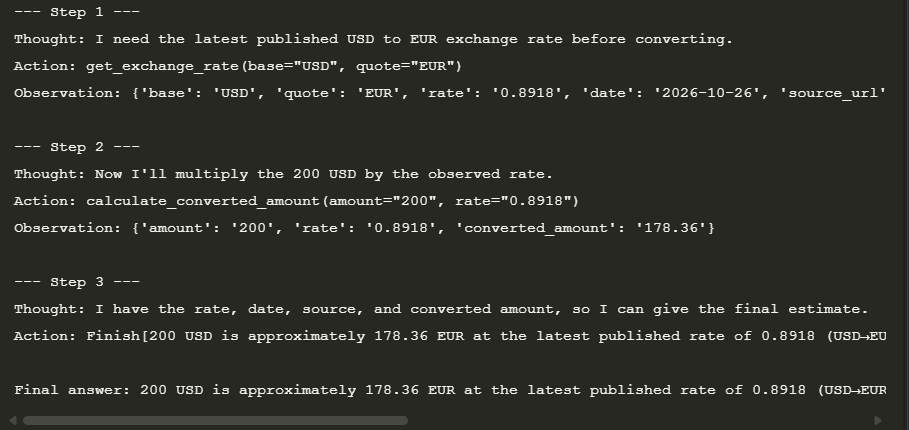

## 3.Plan-and-Solve

Plan-and-Solce is more like an architect who must first draw a complete blueprint before starting consstruction, then build according to the blueprint

- **Planning**:The agent recevies the quetsion. The plan-and-solve decompose the problem and formulate a clear, step-by-step action plan
- **Solving**: The agent will execute ccording to the steps in the plan. Each step may be an independent LLM call or processing of the previous step's results, until all steps in the plan are completed and the final answer is obtained.

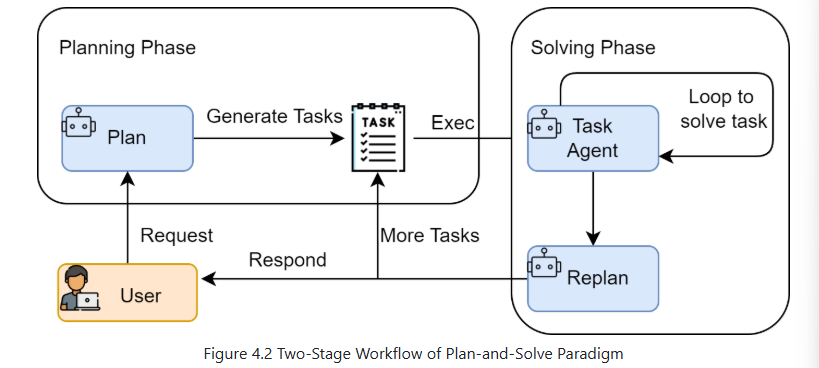

Plan-and-solve is suitable for complex tasks with strong structure 
- Multi-step math word problems: Need to first list calculation steps, then solve one by one
- Report writing integrating multiple information sources: Need to plan the report structure, then fill in content
- Code generation tasks: Need to conceive the structure of functions, classes and modules then implement one by one

### 3.1 Plaaning

In order to highlight the advantage of structural reasoning. We will just use a prompt to finish a reasoning task.

The question is : A fruit store sold 15 apples on Monday. The number of apples sold on Tuesday was twice that of Monday. The number sold on Wednesday was 5 fewer than Tuesday. How many apples were sold in total over these three days?

In [17]:
PLANNER_PROMPT_TEMPLATE = """
You are a top AI planning expert. Your task is to decompose complex problems posed by users into an action plan consisting of multiple simple steps.
Please ensure that each step in the plan is an independent, executable subtask and is strictly arranged in logical order.
Your output must be a Python list, where each element is a string describing a subtask.

Question: {question}

Please strictly output your plan in the following format, with ```python and ``` as prefix and suffix being necessary:
```
["Step 1", "Step 2", "Step 3", ...]
"""

In [18]:
import ast

class Planner:
    def __init__(self, llm_client):
        self.llm_client = llm_client

    def plan(self, question: str) -> list[str]:
        """
        Generate an action plan based on user question.
        """
        prompt = PLANNER_PROMPT_TEMPLATE.format(question=question)

        # To generate a plan, we build a simple message list
        messages = [{"role": "user", "content": prompt}]

        print("--- Generating Plan ---")
        # Use streaming output to get the complete plan
        response_text = self.llm_client.think(messages=messages) or ""

        print(f"Plan Generated:\n{response_text}")

        # Parse the list string output by LLM
        try:
            # Find content between ```python and ```
            plan_str = response_text.split("```python")[1].split("```")[0].strip()
            # Use ast.literal_eval to safely execute the string and convert it to a Python list
            plan = ast.literal_eval(plan_str)
            return plan if isinstance(plan, list) else []
        except (ValueError, SyntaxError, IndexError) as e:
            print(f"Error parsing plan: {e}")
            print(f"Raw response: {response_text}")
            return []
        except Exception as e:
            print(f"Unknown error occurred while parsing plan: {e}")
            return []

## 3.2 Executive

Executor not only invocate the LLM to finish subquestions, but also play an important role: managing the state. It records the results from every step and make these results provide the context to the next steps, ensuring the chain of tasks smoothly. So, the prompt needs 4 key information:

- original questions: ensuring models understand the final target
- plan: let model know the current step in the whole process
- history: make the finished work to be next input
- Current: tell the model what it the current question

In [19]:
EXECUTOR_PROMPT_TEMPLATE = """
You are a top AI execution expert. Your task is to strictly follow the given plan and solve the problem step by step.
You will receive the original question, the complete plan, and the steps and results completed so far.
Please focus on solving the "current step" and only output the final answer for that step, without any additional explanations or dialogue.

# Original Question:
{question}

# Complete Plan:
{plan}

# Historical Steps and Results:
{history}

# Current Step:
{current_step}

Please only output the answer for the "current step":
"""

Encapsulating the execution logic into the Executor calss

In [20]:
class Executor:
    def __init__(self, llm_client):
        self.llm_client = llm_client

    def execute(self, question: str, plan: list[str]) -> str:
        """
        Execute step by step according to the plan and solve the problem.
        """
        history = ""  # String to store historical steps and results

        print("\n--- Executing Plan ---")

        for i, step in enumerate(plan):
            print(f"\n-> Executing step {i+1}/{len(plan)}: {step}")

            prompt = EXECUTOR_PROMPT_TEMPLATE.format(
                question=question,
                plan=plan,
                history=history if history else "None",  # If it's the first step, history is empty
                current_step=step
            )

            messages = [{"role": "user", "content": prompt}]

            response_text = self.llm_client.think(messages=messages) or ""

            # Update history for the next step
            history += f"Step {i+1}: {step}\nResult: {response_text}\n\n"

            print(f"Step {i+1} completed, result: {response_text}")

        # After the loop ends, the last step's response is the final answer
        final_answer = response_text
        return final_answer

ReAct: actoin-observation

Plan-and-solve: step-results

In [21]:
class PlanAndSolveAgent:
    def __init__(self, llm_client):
        """
        Initialize the agent and create planner and executor instances.
        """
        self.llm_client = llm_client
        self.planner = Planner(self.llm_client)
        self.executor = Executor(self.llm_client)

    def run(self, question: str):
        """
        Run the agent's complete process: plan first, then execute.
        """
        print(f"\n--- Starting to Process Question ---\nQuestion: {question}")

        # 1. Call planner to generate plan
        plan = self.planner.plan(question)

        # Check if plan was successfully generated
        if not plan:
            print("\n--- Task Terminated --- \nUnable to generate valid action plan.")
            return

        # 2. Call executor to execute plan
        final_answer = self.executor.execute(question, plan)
        print(f"\n--- Task Completed ---\nFinal Answer: {final_answer}")
        return final_answer

In [22]:
llm_client = HelloAgentsLLM()
agent = PlanAndSolveAgent(llm_client)
agent.run("A fruit store sold 15 apples on Monday. The number of apples sold on Tuesday was twice "
          "that of Monday. The number sold on Wednesday was 5 fewer than Tuesday. How many apples "
          "were sold in total over these three days?")


--- Starting to Process Question ---
Question: A fruit store sold 15 apples on Monday. The number of apples sold on Tuesday was twice that of Monday. The number sold on Wednesday was 5 fewer than Tuesday. How many apples were sold in total over these three days?
--- Generating Plan ---
Calling deepseek-v4-pro model...
Large language model response successful:
```python
["Identify the number of apples sold on Monday from the problem statement.", 
 "Calculate the number of apples sold on Tuesday by doubling Monday's sales.", 
 "Calculate the number of apples sold on Wednesday by subtracting 5 from Tuesday's sales.", 
 "Add the sales from Monday, Tuesday, and Wednesday to find the total number of apples sold."]
```
Plan Generated:
```python
["Identify the number of apples sold on Monday from the problem statement.", 
 "Calculate the number of apples sold on Tuesday by doubling Monday's sales.", 
 "Calculate the number of apples sold on Wednesday by subtracting 5 from Tuesday's sales.", 


'70'

# 4.Reflection

The core idea of the Reflection mechanism is to introduce a post-hoc self-correction loop

### 4.1 Core idea of reflection mechanism

- Execution: Agent attempts to complete the task using familiar methods, generating a preliminary solution or action trajectory
- Reflection: Agent invocates an independent LLM instance or change a specific prompt to be a reviewer. Check factual errors, logicaal flaws, efficiency issues, missing information
- Refinement: Agent use first draft and feedback as new context, calls the LLM agagin, and asks it to revise the first draft based on the feedbcak

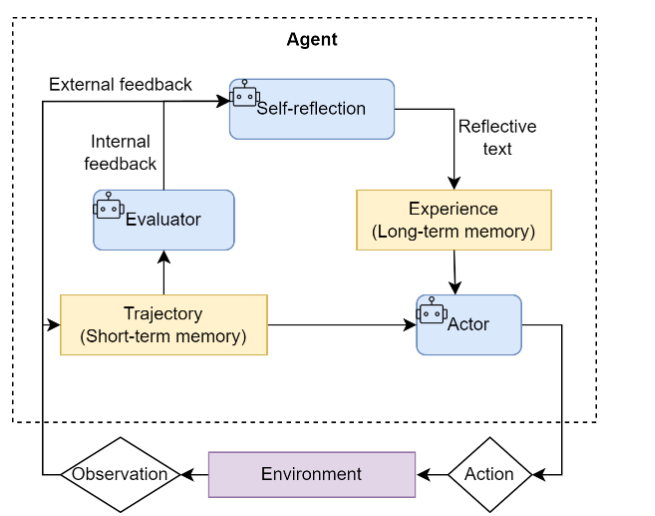

### 4.2 Case setting and memory module design

We focus on the code generation and iterative optimization

**The goal task for this step is: "Write a Python function to find all prime numbers between 1 and n."**

This task is an excellent scenario for testin the reflection mechanism:
- Clear Optimization Path Exists: The code initially generated by the large language model is likely a simple but inefficient recursive implementation.
- Clear Reflection Points: Through reflection, problems like "excessively high time complexity" or "redundant calculations" can be discovered.
- Clear Optimization Direction: Based on feedback, it can be optimized to a more efficient iterative version or a version using the memoization pattern.

**The core of Reflection is iteration and the prerequisite for iteraton is the ability to remember previous attempts and received feedback. So, the "short-term memory" module is essential for implementing this paradigm. This memory module will be responsible for storing the complete trajectory of each "execute-reflect" loop.**

In [28]:
from typing import List, Dict, Any, Optional

class Memory:
    """
    A simple short-term memory module for storing the agent's action and reflection trajectory.
    """
    def __init__(self):
        """
        Initialize an empty list to store all records.
        """
        self.records: List[Dict[str, Any]] = []

    def add_record(self, record_type: str, content: str):
        """
        Add a new record to memory.

        Parameters:
        - record_type (str): Type of record ('execution' or 'reflection').
        - content (str): Specific content of the record (e.g., generated code or reflection feedback).
        """
        record = {"type": record_type, "content": content}
        self.records.append(record)
        print(f"Memory updated, added a '{record_type}' record.")

    def get_trajectory(self) -> str:
        """
        Format all memory records into a coherent string text for building prompts.
        """
        trajectory_parts = []
        for record in self.records:
            if record['type'] == 'execution':
                trajectory_parts.append(f"--- Previous Attempt (Code) ---\n{record['content']}")
            elif record['type'] == 'reflection':
                trajectory_parts.append(f"--- Reviewer Feedback ---\n{record['content']}")
        return "\n\n".join(trajectory_parts)

    def get_last_execution(self) -> Optional[str]:
        """
        Get the most recent execution result (e.g., the latest generated code).
        Returns None if it doesn't exist.
        """
        for record in reversed(self.records):
            if record['type'] == 'execution':
                return record['content']
        return None

- add_record: adding new item to the memory
- get_trajectory: serialize the memory trajectory into a text segment that can be directly inserted into subsequent prompts, providign complete context for the model's reflection and optimization
- get_last_execution: makes it convenient to obtain the latest "first_draft" for reflection

### 4.2.1 Prompt

Reflection needs more prompts, representing differents roles and corporating seperately.

In [29]:
INITIAL_PROMPT_TEMPLATE = """
You are a senior Python programmer. Please write a Python function according to the following requirements.
Your code must include a complete function signature, docstring, and follow PEP 8 coding standards.

Requirement: {task}

Please output the code directly without any additional explanations.
"""

In [30]:
REFLECT_PROMPT_TEMPLATE = """
You are an extremely strict code review expert and senior algorithm engineer with ultimate requirements for code performance.
Your task is to review the following Python code and focus on finding its main bottlenecks in <strong>algorithm efficiency</strong>.

# Original Task:
{task}

# Code to Review:
```python
{code}
Please analyze the time complexity of this code and consider whether there is an <strong>algorithmically superior</strong> solution to significantly improve performance.
If one exists, please clearly point out the deficiencies of the current algorithm and propose specific, feasible algorithm improvement suggestions (e.g., using sieve method instead of trial division).
Only if the code has reached optimality at the algorithm level can you answer “no improvement needed.”

Please output your feedback directly without any additional explanations.
"""

In [31]:
REFINE_PROMPT_TEMPLATE = """
You are a senior Python programmer. You are optimizing your code based on feedback from a code review expert.

# Original Task:
{task}

# Your Previous Code Attempt:
{last_code_attempt}

Reviewer's Feedback:
{feedback}

Please generate an optimized new version of the code based on the reviewer's feedback.
Your code must include a complete function signature, docstring, and follow PEP 8 coding standards.
Please output the optimized code directly without any additional explanations.
"""

### 4.2.1 Agent encapsulation

In [32]:
class ReflectionAgent:
    def __init__(self, llm_client, max_iterations=3):
        self.llm_client = llm_client
        self.memory = Memory()
        self.max_iterations = max_iterations

    def run(self, task: str):
        print(f"\n--- Starting to Process Task ---\nTask: {task}")

        # --- 1. Initial Execution ---
        print("\n--- Performing Initial Attempt ---")
        initial_prompt = INITIAL_PROMPT_TEMPLATE.format(task=task)
        initial_code = self._get_llm_response(initial_prompt)
        self.memory.add_record("execution", initial_code)

        # --- 2. Iterative Loop: Reflection and Refinement ---
        for i in range(self.max_iterations):
            print(f"\n--- Iteration {i+1}/{self.max_iterations} ---")

            # a. Reflection
            print("\n-> Performing Reflection...")
            last_code = self.memory.get_last_execution()
            reflect_prompt = REFLECT_PROMPT_TEMPLATE.format(task=task, code=last_code)
            feedback = self._get_llm_response(reflect_prompt)
            self.memory.add_record("reflection", feedback)

            # b. Check if stopping is needed
            if "no improvement needed" in feedback.lower():
                print("\nReflection considers code needs no improvement, task completed.")
                break

            # c. Refinement
            print("\n-> Performing Refinement...")
            refine_prompt = REFINE_PROMPT_TEMPLATE.format(
                task=task,
                last_code_attempt=last_code,
                feedback=feedback
            )
            refined_code = self._get_llm_response(refine_prompt)
            self.memory.add_record("execution", refined_code)

        final_code = self.memory.get_last_execution()
        print(f"\n--- Task Completed ---\nFinal Generated Code:\n{final_code}")
        return final_code

    def _get_llm_response(self, prompt: str) -> str:
        """A helper method for calling LLM and getting complete streaming response."""
        messages = [{"role": "user", "content": prompt}]
        response_text = self.llm_client.think(messages=messages) or ""
        return response_text

- Review --> check whether stop --> optimizatoin or not
- when reviewer say "no improvement needed" or get the max_iterations --> stop

In [33]:
llm_client = HelloAgentsLLM()
agent = ReflectionAgent(llm_client, max_iterations=2)
agent.run("Write a Python function to find all prime numbers between 1 and n.")


--- Starting to Process Task ---
Task: Write a Python function to find all prime numbers between 1 and n.

--- Performing Initial Attempt ---
Calling deepseek-v4-pro model...
Large language model response successful:
```python
def primes_up_to_n(n: int) -> list[int]:
    """
    Return a list of all prime numbers between 1 and n inclusive.

    Args:
        n (int): The upper bound of the range to check for primes.

    Returns:
        list[int]: A list of prime numbers in the range [1, n].

    Raises:
        ValueError: If n is less than 1.
    """
    if n < 1:
        raise ValueError("n must be at least 1")

    primes = []
    for num in range(2, n + 1):
        is_prime = True
        for divisor in range(2, int(num ** 0.5) + 1):
            if num % divisor == 0:
                is_prime = False
                break
        if is_prime:
            primes.append(num)
    return primes
```
Memory updated, added a 'execution' record.

--- Iteration 1/2 ---

-> Performing Ref

'```python\ndef primes_up_to_n(n: int) -> list[int]:\n    """\n    Return a list of all prime numbers between 1 and n inclusive.\n\n    This implementation uses the Sieve of Eratosthenes with an\n    odd-only optimization and direct index assignment to reduce\n    memory allocation overhead during marking.\n\n    Args:\n        n (int): The upper bound of the range to check for primes.\n\n    Returns:\n        list[int]: A list of prime numbers in the range [1, n].\n\n    Raises:\n        ValueError: If n is less than 1.\n    """\n    if n < 1:\n        raise ValueError("n must be at least 1")\n    if n < 2:\n        return []\n\n    # Only track odd numbers: index i represents number 2*i + 3\n    size = (n - 1) // 2\n    is_prime = bytearray(b"\\x01") * (size + 1)\n\n    limit = int(n ** 0.5)\n    for i in range(0, (limit - 1) // 2 + 1):\n        if is_prime[i]:\n            prime = 2 * i + 3\n            start = (prime * prime - 3) // 2\n            step = prime\n            for j in

# Chapter 4 Summary

## 1. Overview

| | ReAct | Plan-and-Solve | Reflection |
|---|---|---|---|
| Core idea | Interleave thinking and acting; each Observation shapes the next step | Plan the whole task first, then execute the plan step by step | Produce a draft, critique it, refine it, and repeat |
| Analogy | A detective following clues | An architect drawing the blueprint before building | A writer working with a strict editor |
| Origin | Yao et al., 2022 (ICLR 2023) | Wang et al., 2023 | Shinn et al., 2023 (Reflexion) |
| How thinking and acting are organized | Think while doing | Think first, then do | Do first, then review |
| Where corrections come from | External: tool Observations | Almost nowhere (the plan is static) | Internal: a reviewer LLM |
| State it keeps | History of Action + Observation (the book drops Thought) | History of Step + Result | Memory records: `execution` and `reflection` |
| Uses tools in the book | Yes (search; our version: `ExchangeRate`) | No (pure reasoning) | No (code generation) |
| Book example | Huawei's latest phone (ours: currency conversion) | Apple-sales word problem | Function that finds primes from 1 to n |

## 2. Workflow

| | ReAct | Plan-and-Solve | Reflection |
|---|---|---|---|
| Stages | 1. Fill tools, question and history into the prompt<br>2. LLM outputs Thought + Action<br>3. Parse Thought, Action, tool name and input<br>4. Run the tool, or return on `Finish`<br>5. Append Action + Observation to history, then loop | 1. Planner: one LLM call turns the question into a Python list of steps<br>2. Executor: solve step i using the question, the full plan and earlier results<br>3. Append "Step i / Result" to history<br>4. The last step's result is the answer | 1. Write the first draft<br>2. Reviewer critiques the latest draft<br>3. Stop if the feedback says "no improvement needed"<br>4. Otherwise rewrite using draft + feedback<br>5. Store each draft and feedback in Memory, then loop |
| Key components | `REACT_PROMPT_TEMPLATE`, `ToolExecutor`, `_parse_output`, `_parse_action` | `PLANNER_PROMPT_TEMPLATE`, `Planner`, `ast.literal_eval`, `EXECUTOR_PROMPT_TEMPLATE`, `Executor` | `Memory`, `INITIAL_PROMPT_TEMPLATE`, `REFLECT_PROMPT_TEMPLATE`, `REFINE_PROMPT_TEMPLATE` |
| Stop condition | `Finish[...]` or `max_steps` | All steps executed (an empty plan ends the run immediately) | Reviewer says "no improvement needed", or `max_iterations` |
| LLM calls per run | One per step | 1 + number of steps | At most 1 + 2k (k = rounds) |
| Book run | 2 steps | 5 calls (1 plan + 4 steps) | 4 calls (stopped in round 2) |

## 3. When to Use

| | Good fit | Poor fit | Example tasks |
|---|---|---|---|
| ReAct | The next step depends on what you just found; real-time or external information; exact calculation handed to a tool; API or database calls | Long tasks that need a global plan; latency-sensitive tasks with many steps; models that can't follow a strict format | Q&A with search, currency conversion, customer-service lookups |
| Plan-and-Solve | Tasks with a clear structure that can be broken down up front | Exploratory tasks where information appears along the way; environments that change mid-run | Multi-step math, reports with a known outline, code with a known module layout |
| Reflection | Quality and reliability matter more than speed | Real-time responses; tasks where "roughly right" is enough; tasks with no way to judge quality | Critical business code, technical reports, complex reasoning |

## 4. Pros and Cons

| | Pros | Cons |
|---|---|---|
| ReAct | Interpretable: every step has a visible Thought<br>Corrects itself as it goes, based on Observations<br>Combines LLM reasoning with tool accuracy | Depends heavily on the model's reasoning and format-following<br>Serial calls are slow and costly<br>Fragile prompt: small wording changes alter behavior<br>No global plan, so it can hit local optima or spin in place |
| Plan-and-Solve | Clear structure and steady focus on the goal<br>Each step gets a short, focused prompt<br>The plan can be inspected before anything runs | A wrong plan is executed faithfully to the end<br>No recovery when a step fails<br>Calls grow with the number of steps<br>The plan parser is fragile |
| Reflection | Can turn an acceptable answer into an excellent one<br>Catches logic gaps, inefficiency and edge cases<br>The draft-and-feedback trail works as short-term memory | Extra calls and latency every round<br>Three prompts to design and debug<br>The same model reviewing itself shares its own blind spots<br>The stop condition is fragile |

## 5. What You Might Not Have Thought Of

### ReAct

| Finding | Why it matters |
|---|---|
| The model can write past its turn: it may invent an Observation, or add a premature `Finish` full of placeholders. Your run produced `Finish[... [result] CNY.]` | The book's `re.DOTALL` Action regex swallows the extra text into the tool input |
| Thought and Action on the same line (seen in your run) | The book's Thought regex expects a newline before `Action:`, so the Thought absorbs the Action text |
| A multi-line `Finish[...]` | The book's code crashes with `AttributeError` because its `Finish` regex has no `re.DOTALL` |
| `**Thought**:` written in markdown bold | Nothing matches and the run stops |
| Parse failure followed by a silent `continue` | At `temperature=0` the next prompt is identical, so the model repeats the same mistake until `max_steps` |
| History keeps no Thought (book design) | Saves tokens, but the model loses its own earlier reasoning |
| Strict input validation inside the tool | It was your last line of defense: `ExchangeRate` rejected the swallowed `Finish` |
| Error messages that include the fix (e.g. the expected input format) | The model corrected itself on the very next step |
| `Tool[input]` takes only one string | Multi-argument tools need ad-hoc formats, which is why Chapter 7 moves to native function calling |
| 50–100 tools in a single prompt | Descriptions crowd the context and tool choice gets worse; you need tool retrieval or grouping |
| The full prompt is re-sent every step | Cost grows as the history grows |

### Plan-and-Solve

| Finding | Why it matters |
|---|---|
| In the book's log the plan already contains the answers ("= 30", "= 70") | The executor only copies them, and any error made while planning carries through to the end |
| The parser only accepts a code block tagged `python` | A `json` tag, no code fence, or a numbered list means an empty plan, and the task ends |
| The plan is static | Real systems add a replanner after each step: continue, revise the remaining steps, or finish (Plan-and-Execute) |
| "The last step's output is the final answer" | A hidden assumption that breaks if the last step isn't "give the answer" |
| Every step runs serially | Steps that don't depend on each other could run in parallel |
| The book's version uses no tools | In practice each step's executor is often a ReAct agent |

### Reflection

| Finding | Why it matters |
|---|---|
| The stop check is a substring match | A negated sentence ("It is wrong to say no improvement needed") stops it falsely; rewording ("No further improvement is needed") or another language means it never stops |
| `get_trajectory()` is defined but never called | The reviewer can't see its earlier feedback, so it may repeat itself or swing between versions |
| A failed LLM call returns `""`, which is stored as the newest code | One timeout in the last refine round empties the final result |
| The reflect prompt wraps code that is already fenced | The reviewer sees nested code fences |
| The reviewer wrote "Improved code as follows" | Role drift: the critic started doing the refiner's job |
| The review criteria set the direction | A reviewer focused only on efficiency will never improve readability |
| Self-critique without an external signal can turn right answers wrong (Huang et al., 2023) | Reflexion relies on evaluation signals; ground reflection in real tests or timings |
| The book says cost grows "exponentially" | Calls grow linearly (1 + 2k); only tokens grow faster, and only if the whole trajectory is fed back in |
| Output mirrors the prompt's style | The `<strong>` tags in the prompt showed up in the reviewer's reply |

### Across All Three

| Lesson | In practice |
|---|---|
| Don't let the LLM decide what code can check | Business rules, arithmetic and validation belong in code or tools |
| Turn errors into Observations that say how to fix them | Self-correction only works if the model is told what went wrong |
| Defend in layers | Prompt rules, then a tolerant parser, then strict tool validation |
| Turn real failures into regression tests | Your two logged outputs are now `assert` cases |
| Test the loop with a scripted LLM | Checks parsing and control flow without API cost |
| Combine the paradigms | Plan with Plan-and-Solve, run each step with ReAct, replan on failure, then use Reflection for a final quality check (the pattern behind Chapter 14's DeepResearch) |
| Choose the model per role | A fast model for execution and a strong model for review can cut cost without losing quality |